Step 1: Import the required libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Deep learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, LSTM, Dense, Dropout

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

Step 2: Load the dataset

In [3]:
df = pd.read_csv('/content/Sentiment.csv')

# Display first five rows
df.head()

,id,candidate,candidate_confidence,relevant_yn,relevant_yn_confidence,sentiment,sentiment_confidence,subject_matter,subject_matter_confidence,candidate_gold,...,relevant_yn_gold,retweet_count,sentiment_gold,subject_matter_gold,text,tweet_coord,tweet_created,tweet_id,tweet_location,user_timezone
0,1,No candidate mentioned,1.0,yes,1.0,Neutral,0.6578,None of the above,1.0000,NaN,...,NaN,5,NaN,NaN,RT @NancyLeeGrahn: How did everyone feel about...,NaN,2015-08-07 09:54:46 -0700,629697200650592256,NaN,Quito
1,2,Scott Walker,1.0,yes,1.0,Positive,0.6333,None of the above,1.0000,NaN,...,NaN,26,NaN,NaN,RT @ScottWalker: Didn't catch the full #GOPdeb...,NaN,2015-08-07 09:54:46 -0700,629697199560069120,NaN,NaN
2,3,No candidate mentioned,1.0,yes,1.0,Neutral,0.6629,None of the above,0.6629,NaN,...,NaN,27,NaN,NaN,RT @TJMShow: No mention of Tamir Rice and the ...,NaN,2015-08-07 09:54:46 -0700,629697199312482304,NaN,NaN
3,4,No candidate mentioned,1.0,yes,1.0,Positive,1.0000,None of the above,0.7039,NaN,...,NaN,138,NaN,NaN,RT @RobGeorge: That Carly Fiorina is trending ...,NaN,2015-08-07 09:54:45 -0700,629697197118861312,Texas,Central Time (US & Canada)
4,5,Donald Trump,1.0,yes,1.0,Positive,0.7045,None of the above,1.0000,NaN,...,NaN,156,NaN,NaN,RT @DanScavino: #GOPDebate w/ @realDonaldTrump...,NaN,2015-08-07 09:54:45 -0700,629697196967903232,NaN,Arizona


Step 2.1: Understand the dataset

In [4]:
# Display dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (13871, 21)


In [5]:
# Display column names
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['id', 'candidate', 'candidate_confidence', 'relevant_yn',
       'relevant_yn_confidence', 'sentiment', 'sentiment_confidence',
       'subject_matter', 'subject_matter_confidence', 'candidate_gold', 'name',
       'relevant_yn_gold', 'retweet_count', 'sentiment_gold',
       'subject_matter_gold', 'text', 'tweet_coord', 'tweet_created',
       'tweet_id', 'tweet_location', 'user_timezone'],
      dtype='object')


In [6]:
# Display information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13871 entries, 0 to 13870
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         13871 non-null  int64  
 1   candidate                  13775 non-null  object 
 2   candidate_confidence       13871 non-null  float64
 3   relevant_yn                13871 non-null  object 
 4   relevant_yn_confidence     13871 non-null  float64
 5   sentiment                  13871 non-null  object 
 6   sentiment_confidence       13871 non-null  float64
 7   subject_matter             13545 non-null  object 
 8   subject_matter_confidence  13871 non-null  float64
 9   candidate_gold             28 non-null     object 
 10  name                       13871 non-null  object 
 11  relevant_yn_gold           32 non-null     object 
 12  retweet_count              13871 non-null  int64  
 13  sentiment_gold             15 non-null     obj

In [7]:
# Check first five records
df.head()

,id,candidate,candidate_confidence,relevant_yn,relevant_yn_confidence,sentiment,sentiment_confidence,subject_matter,subject_matter_confidence,candidate_gold,...,relevant_yn_gold,retweet_count,sentiment_gold,subject_matter_gold,text,tweet_coord,tweet_created,tweet_id,tweet_location,user_timezone
0,1,No candidate mentioned,1.0,yes,1.0,Neutral,0.6578,None of the above,1.0000,NaN,...,NaN,5,NaN,NaN,RT @NancyLeeGrahn: How did everyone feel about...,NaN,2015-08-07 09:54:46 -0700,629697200650592256,NaN,Quito
1,2,Scott Walker,1.0,yes,1.0,Positive,0.6333,None of the above,1.0000,NaN,...,NaN,26,NaN,NaN,RT @ScottWalker: Didn't catch the full #GOPdeb...,NaN,2015-08-07 09:54:46 -0700,629697199560069120,NaN,NaN
2,3,No candidate mentioned,1.0,yes,1.0,Neutral,0.6629,None of the above,0.6629,NaN,...,NaN,27,NaN,NaN,RT @TJMShow: No mention of Tamir Rice and the ...,NaN,2015-08-07 09:54:46 -0700,629697199312482304,NaN,NaN
3,4,No candidate mentioned,1.0,yes,1.0,Positive,1.0000,None of the above,0.7039,NaN,...,NaN,138,NaN,NaN,RT @RobGeorge: That Carly Fiorina is trending ...,NaN,2015-08-07 09:54:45 -0700,629697197118861312,Texas,Central Time (US & Canada)
4,5,Donald Trump,1.0,yes,1.0,Positive,0.7045,None of the above,1.0000,NaN,...,NaN,156,NaN,NaN,RT @DanScavino: #GOPDebate w/ @realDonaldTrump...,NaN,2015-08-07 09:54:45 -0700,629697196967903232,NaN,Arizona


Step 2.2: Select the required columns

In [8]:
df = df[['candidate', 'sentiment', 'text']]

In [9]:
df.head()

,candidate,sentiment,text
0,No candidate mentioned,Neutral,RT @NancyLeeGrahn: How did everyone feel about...
1,Scott Walker,Positive,RT @ScottWalker: Didn't catch the full #GOPdeb...
2,No candidate mentioned,Neutral,RT @TJMShow: No mention of Tamir Rice and the ...
3,No candidate mentioned,Positive,RT @RobGeorge: That Carly Fiorina is trending ...
4,Donald Trump,Positive,RT @DanScavino: #GOPDebate w/ @realDonaldTrump...


Step 2.3: Check missing values

In [10]:
print(df.isnull().sum())

candidate    96
sentiment     0
text          0
dtype: int64


In [11]:
df = df.dropna(subset=['candidate'])

In [12]:
print("Dataset shape after removing missing values:", df.shape)

Dataset shape after removing missing values: (13775, 3)


In [13]:
df.isnull().sum()

,0
candidate,0
sentiment,0
text,0


Step 2.4: Check sentiment distribution

In [14]:
print(df['sentiment'].value_counts())

sentiment
Negative    8447
Neutral     3106
Positive    2222
Name: count, dtype: int64


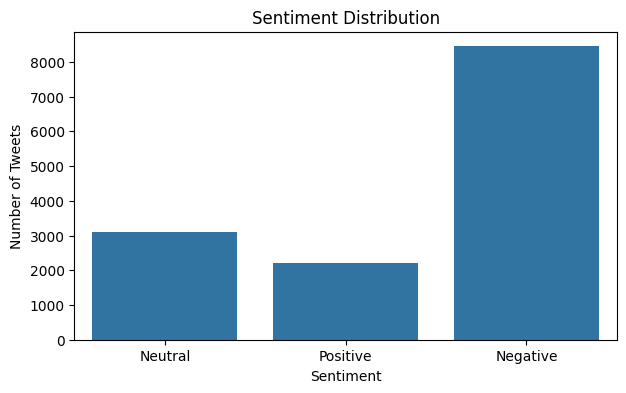

In [15]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='sentiment')

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

Step 3: Text preprocessing

In [16]:
# Load stopwords
stop_words = set(stopwords.words('english'))

In [17]:
# Preserve negation words because they are important for sentiment
stop_words = stop_words - {'not', 'no', 'nor'}

In [19]:
# Text cleaning function
def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove mentions
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol but retain the word
    text = re.sub(r'#', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()

    words = [word for word in words if word not in stop_words]

    # Join words
    text = ' '.join(words)

    return text

In [20]:
df['cleaned_text'] = df['text'].apply(clean_text)

In [21]:
df[['text', 'cleaned_text']].head(10)

,text,cleaned_text
0,RT @NancyLeeGrahn: How did everyone feel about...,rt everyone feel climate change question last ...
1,RT @ScottWalker: Didn't catch the full #GOPdeb...,rt didnt catch full gopdebate last night scott...
2,RT @TJMShow: No mention of Tamir Rice and the ...,rt no mention tamir rice gopdebate held clevel...
3,RT @RobGeorge: That Carly Fiorina is trending ...,rt carly fiorina trending hours debate men jus...
4,RT @DanScavino: #GOPDebate w/ @realDonaldTrump...,rt gopdebate w delivered highest ratings histo...
5,"RT @GregAbbott_TX: @TedCruz: ""On my first day ...",rt first day rescind every illegal executive a...
6,RT @warriorwoman91: I liked her and was happy ...,rt liked happy heard going moderator not anymo...
7,Going on #MSNBC Live with @ThomasARoberts arou...,going msnbc live around pm et gopdebate
8,Deer in the headlights RT @lizzwinstead: Ben C...,deer headlights rt ben carson may brain surgeo...
9,RT @NancyOsborne180: Last night's debate prove...,rt last nights debate proved gopdebate batsask...


Step 4: Text vectorization – Tokenization and Padding

4.1 Tokenization

In [22]:
X = df['cleaned_text']
y = df['sentiment']

In [23]:
y = y.astype(str).str.strip().str.lower()

print(y.value_counts())

sentiment
negative    8447
neutral     3106
positive    2222
Name: count, dtype: int64


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (11020,)
Testing data: (2755,)


In [25]:
vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token='<OOV>'
)

# Fit tokenizer only on training text
tokenizer.fit_on_texts(X_train)

# Convert training text into sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)

# Convert testing text into sequences
X_test_sequences = tokenizer.texts_to_sequences(X_test)

print(X_train_sequences[:5])

[[3, 30, 5, 262, 38, 104, 271, 63, 5, 263, 2, 4], [199, 335, 5207, 133, 24, 8, 4], [95, 190, 248, 834, 2], [3, 1044, 2, 239, 513, 793, 459, 33, 486, 361, 20, 3654, 1289, 2437], [3, 96, 75, 24, 335, 2438, 285, 1188, 278, 871, 2890, 15, 286, 2891]]


4.2 Padding

In [26]:
sequence_lengths = [len(seq) for seq in X_train_sequences]

max_length = int(np.percentile(sequence_lengths, 95))

max_length = max(max_length, 1)

print("Maximum sequence length:", max_length)

Maximum sequence length: 15


In [27]:
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [28]:
X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [29]:
print("Training padded shape:", X_train_padded.shape)
print("Testing padded shape:", X_test_padded.shape)

Training padded shape: (11020, 15)
Testing padded shape: (2755, 15)


Step 5: Encode the sentiment labels

In [31]:
# Initialize label encoder
label_encoder = LabelEncoder()

# Fit on training labels
y_train_encoded = label_encoder.fit_transform(y_train)

# Transform testing labels
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

Classes: ['negative' 'neutral' 'positive']


In [32]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train_encoded, num_classes=3)

y_test_cat = to_categorical(y_test_encoded, num_classes=3)

print("Training labels shape:", y_train_cat.shape)
print("Testing labels shape:", y_test_cat.shape)

Training labels shape: (11020, 3)
Testing labels shape: (2755, 3)


Step 6: Develop the deep learning model

6.1 Build the model

In [33]:
model = Sequential()

In [34]:
# Embedding layer
model.add(Embedding(
    input_dim=vocab_size,
    output_dim=100,
    input_length=max_length
))

# Spatial Dropout
model.add(SpatialDropout1D(0.2))

# LSTM layer
model.add(LSTM(128, dropout=0.2, recurrent_dropout=0.0))

# Output layer
model.add(Dense(3, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [35]:
# Compile model
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [36]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Step 7: Train the model

In [37]:
from tensorflow.keras.callbacks import EarlyStopping

In [38]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [39]:
history = model.fit(
    X_train_padded,
    y_train_cat,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.6397 - loss: 0.8450 - val_accuracy: 0.6629 - val_loss: 0.7875
Epoch 2/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.7205 - loss: 0.6609 - val_accuracy: 0.6806 - val_loss: 0.7724
Epoch 3/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.7940 - loss: 0.5257 - val_accuracy: 0.6724 - val_loss: 0.8323
Epoch 4/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 13s 47ms/step - accuracy: 0.8325 - loss: 0.4327 - val_accuracy: 0.6547 - val_loss: 0.8456
Epoch 5/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.8583 - loss: 0.3693 - val_accuracy: 0.6620 - val_loss: 0.8735


Step 8: Visualize model performance

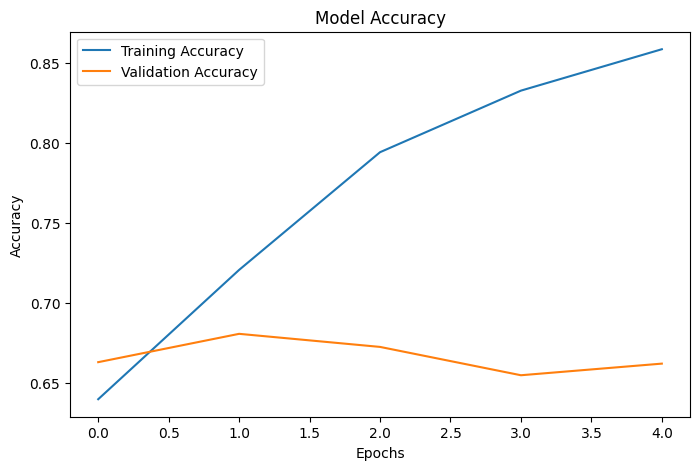

In [40]:
# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

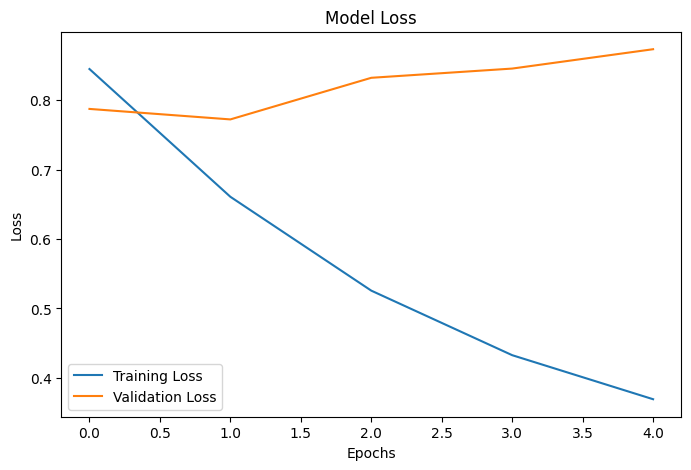

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()

Step 9: Evaluate the model

In [42]:
loss, accuracy = model.evaluate(
    X_test_padded,
    y_test_cat
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6784 - loss: 0.7733
Test Loss: 0.7733093500137329
Test Accuracy: 0.6784029006958008


In [43]:
y_pred_prob = model.predict(X_test_padded)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = y_test_encoded

87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step


In [44]:
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

    negative       0.72      0.88      0.79      1690
     neutral       0.50      0.37      0.42       621
    positive       0.66      0.35      0.46       444

    accuracy                           0.68      2755
   macro avg       0.63      0.53      0.56      2755
weighted avg       0.66      0.68      0.66      2755



Confusion matrix

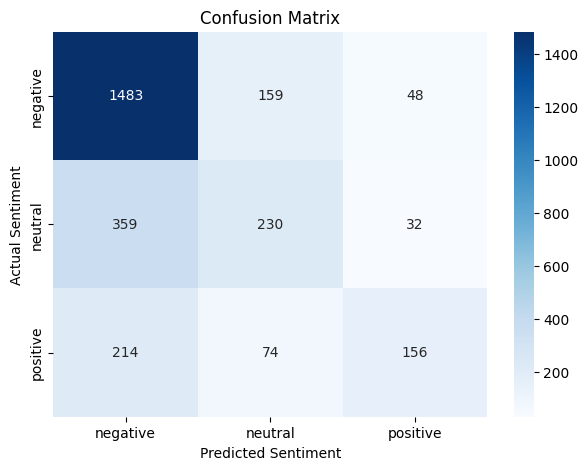

In [45]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

Step 10: Test the model with a new tweet

In [46]:
def predict_sentiment(tweet):

    # Clean the input tweet
    cleaned_tweet = clean_text(tweet)

    # Tokenize
    sequence = tokenizer.texts_to_sequences([cleaned_tweet])

    # Padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    # Predict
    prediction = model.predict(padded_sequence, verbose=0)

    # Get predicted class
    predicted_class = np.argmax(prediction, axis=1)[0]

    # Convert numerical class into sentiment
    sentiment = label_encoder.inverse_transform([predicted_class])[0]

    return sentiment

In [47]:
tweet1 = "I really love this candidate. He is doing amazing work!"

tweet2 = "This candidate is terrible. I completely dislike his work."

tweet3 = "The candidate attended a public meeting today."

print("Tweet 1:", predict_sentiment(tweet1))
print("Tweet 2:", predict_sentiment(tweet2))
print("Tweet 3:", predict_sentiment(tweet3))

Tweet 1: positive
Tweet 2: negative
Tweet 3: neutral
